# What actually costs time when streaming a HATS catalog from Hugging Face

The baseline run (`stream-hf-baseline.ipynb`) split each `InfiniteStream` iteration into
`wait_s` (blocked on the workers) and `post_s` (everything on this process's main thread),
and found `post_s` at **18.5% of wall** on `mmu_ssl_legacysurvey_north`. That is a large
share to leave unattributed, and the standing hypothesis is that it is
`Operation.build` -- called once per partition, from `CatalogStream.submit_next_partitions`.

This notebook splits `post_s` into its parts and tests that hypothesis directly.

It runs **two catalogs chosen to sit on opposite sides of the question**, because
`build` cost turns out to depend on catalog *shape* rather than catalog size:

| catalog | partitions | payload | why it is here |
|---|---|---|---|
| `mmu_ssl_legacysurvey_north` | 5,488 | ~273 KB/row image cutouts | few partitions, enormous bytes |
| `mmu_gaia_gaia` | 33,055 | 11 scalar columns | many partitions, tiny bytes |

`build` is *O(number of partitions in the catalog)* and independent of payload, so if it
ever dominates it will be on the second one.

In [1]:
import cProfile
import io
import os
import platform
import pstats
import socket
from time import perf_counter

import dask
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dask.delayed import Delayed
from dask.distributed import Client, wait

import lsdb
from lsdb.streams import InfiniteStream
from lsdb.streams.catalog_streams import _FakeFuture

# Off JupyterHub, client.dashboard_link raises KeyError: JUPYTERHUB_PUBLIC_URL.
os.environ.setdefault(
    "DASK_DISTRIBUTED__DASHBOARD__LINK", "{scheme}://{host}:{port}/status"
)

plt.rcParams.update({
    "axes.titlesize": 16, "axes.labelsize": 15,
    "xtick.labelsize": 13, "ytick.labelsize": 13,
    "legend.fontsize": 13, "figure.titlesize": 18,
})

print(f"host    {socket.gethostname()}")
print(f"python  {platform.python_version()}")
print(f"lsdb    {lsdb.__version__}")
print(f"dask    {dask.__version__}")

host    sdfiana012
python  3.13.13
lsdb    0.10.5.dev1+g36a32399e
dask    2026.3.0


## Method: a timed replica of `__next__`

`CatalogIterator.__next__` does four things in order -- block on the pending future,
gather it, shuffle the rows, then build and submit the *next* chunk. The baseline could
only separate the first from the rest, because `wait()` is the one seam available from
outside.

To go finer, the cell below **reimplements `__next__` statement for statement with a timer
around each phase**, using only public attributes. lsdb's source is untouched, so what is
measured is the shipped code path, not a modified one.

Two details that matter for the replica being faithful:

- **RNG order is preserved.** `sample(random_state=self.rng)` and `get_next_partitions(...,
  rng)` draw from the same generator, so shuffling *before* selecting partitions -- the
  original order -- means a profiled run sees exactly the chunks an unprofiled one would.
- **`submit_s` means different things per mode.** With a client, `client.compute()` returns
  a `Future` immediately and the fetch happens on workers (showing up in the *next*
  iteration's `wait_s`). With `client=None`, `submit_next_partitions` calls `.compute()`
  inline, so `submit_s` swallows the entire fetch and `wait_s` is meaningless. That is not
  an artifact of the instrumentation -- it is what `client=None` does, and it is why the
  synchronous mode has no prefetch overlap at all.

The phase names below map onto the source as: `result_s` = `self.future.result()`,
`shuffle_s` = `result.sample(...)`, `build_s` = the `operation.build(pixels=[pixel])` loop
inside `_to_delayed`, `graph_s` = the `dask.delayed(pd.concat)` wrapper, `submit_s` = the
handoff.

In [2]:
PHASES = ["wait_s", "result_s", "shuffle_s", "build_s", "graph_s", "submit_s"]


def profiled_next(stream_iter):
    """A phase-timed replica of ``CatalogIterator.__next__``.

    Mirrors ``CatalogIterator.__next__`` and ``CatalogStream.submit_next_partitions``
    from ``lsdb/streams/catalog_streams.py``, using only public attributes.

    Returns ``(chunk, timings)``. Assumes an ``InfiniteStream``, whose
    ``get_next_partitions`` never exhausts ``partitions_left`` -- so the
    end-of-stream branch in the original is unreachable here and is omitted.
    """
    stream = stream_iter.iterable
    distributed = stream.client is not None
    t = {}

    # A -- blocked on the workers. Zero-ish under client=None: the fetch already
    # happened inline during the previous iteration's submit.
    t0 = perf_counter()
    if distributed:
        wait(stream_iter.future)
    t["wait_s"] = perf_counter() - t0

    # B -- future.result(): worker -> client transfer + deserialize.
    # wait() above does NOT cover this; the bytes still have to cross.
    t0 = perf_counter()
    result = stream_iter.future.result()
    t["result_s"] = perf_counter() - t0

    # C -- row shuffle over the gathered frame.
    t0 = perf_counter()
    if stream.shuffle:
        result = result.sample(frac=1, random_state=stream_iter.rng)
    t["shuffle_s"] = perf_counter() - t0

    # D -- pick the next partitions (mutates partitions_left, as the original does).
    stream_iter.partitions_left, parts = stream.get_next_partitions(
        stream_iter.partitions_left, stream_iter.rng
    )

    # E -- THE HYPOTHESIS UNDER TEST: one operation.build() per partition.
    t0 = perf_counter()
    selected = []
    for i in parts:
        pixel = stream._pixels[i]
        built = stream.operation.build(pixels=[pixel])
        selected.append(Delayed(built.pixel_to_key_map[pixel], built.graph))
    t["build_s"] = perf_counter() - t0

    # F -- assemble the delayed concat.
    t0 = perf_counter()
    target = selected[0] if len(selected) == 1 else dask.delayed(pd.concat)(selected)
    t["graph_s"] = perf_counter() - t0

    # G -- hand off. Distributed: returns a Future at once. Sync: runs the fetch inline.
    t0 = perf_counter()
    if distributed:
        stream_iter.future = stream.client.compute(target)
    else:
        stream_iter.future = _FakeFuture(target.compute())
    t["submit_s"] = perf_counter() - t0

    return result, t

In [3]:
def run_profile(catalog, client, n_iters, ppc, label, seed=1):
    """Pull n_iters chunks through the timed replica. One row per chunk."""
    stream = InfiniteStream(
        catalog=catalog, client=client, partitions_per_chunk=ppc, seed=seed
    )
    stream_iter = iter(stream)  # submits chunk 0

    rows = []
    for k in range(n_iters):
        chunk, t = profiled_next(stream_iter)
        t.update(
            chunk=k,
            rows=len(chunk),
            # deep=True reaches the Arrow buffers behind nested columns, so this
            # is real bytes rather than a pointer count.
            nbytes=int(chunk.memory_usage(deep=True).sum()),
        )
        rows.append(t)
        # Drop before the next lands: otherwise two large frames are briefly alive.
        del chunk
        print(
            f"  chunk {k}: "
            + "  ".join(f"{p[:-2]:>7s} {t[p]:6.2f}" for p in PHASES)
            + f" | {t['nbytes'] / 1e6:8.1f} MB"
        )

    # InfiniteStream always leaves one chunk in flight; cancel it or cluster
    # shutdown stalls killing a live task.
    fut = stream_iter.future
    if fut is not None and hasattr(fut, "cancel"):
        fut.cancel()

    df = pd.DataFrame(rows)
    df["config"] = label
    return df

## The catalogs

In [4]:
LEGACY = "hf://datasets/UniverseTBD/mmu_ssl_legacysurvey_north/"
GAIA = "hf://datasets/UniverseTBD/mmu_gaia_gaia@main/mmu_gaia_gaia"

t0 = perf_counter()
cat_legacy = lsdb.open_catalog(LEGACY)
t1 = perf_counter()
cat_gaia = lsdb.open_catalog(GAIA)
t2 = perf_counter()

catalogs = {"legacysurvey": cat_legacy, "gaia": cat_gaia}

pd.DataFrame(
    [
        {
            "catalog": name,
            "npartitions": c.npartitions,
            "ncolumns": len(c.columns),
            "open_s": round(s, 2),
        }
        for (name, c), s in zip(catalogs.items(), [t1 - t0, t2 - t1])
    ]
).set_index("catalog")

,npartitions,ncolumns,open_s
catalog,,,
legacysurvey,5488,15,15.99
gaia,33055,11,14.46


## Experiment 1 -- `build` in isolation

Before touching the network: how long does one `operation.build(pixels=[pixel])` take, and
what does it scale with?

The comparison that matters is **one-pixel-at-a-time against building the whole graph
once**. If per-pixel builds were doing proportional work, `npartitions` of them would cost
about the same as one full build. They do not.

In [5]:
def build_microbench(op, n=25):
    """Mean seconds for one single-pixel build, with cached properties pre-warmed."""
    px = op.healpix_pixels
    op.key_name, op.meta  # warm cached_property so we time the loop, not tokenization
    t0 = perf_counter()
    for k in range(n):
        op.build(pixels=[px[k % len(px)]])
    return (perf_counter() - t0) / n


rows = []
for name, cat in catalogs.items():
    op = cat._operation
    per_pixel = build_microbench(op)

    t0 = perf_counter()
    full = op.build()
    full_s = perf_counter() - t0

    rows.append(
        {
            "catalog": name,
            "npartitions": cat.npartitions,
            "op": type(op).__name__,
            "build_1px_ms": 1e3 * per_pixel,
            "build_all_s": full_s,
            "graph_nodes": len(full.graph),
            # what a full pass costs if you build one pixel at a time, as the stream does
            "epoch_build_s": per_pixel * cat.npartitions,
            "vs_full_build": per_pixel * cat.npartitions / full_s,
        }
    )

build_df = pd.DataFrame(rows).set_index("catalog")
build_df.round(3)

,npartitions,op,build_1px_ms,build_all_s,graph_nodes,epoch_build_s,vs_full_build
catalog,,,,,,,
legacysurvey,5488,FromHealpixMap,1.088,0.030,5488,5.974,200.846
gaia,33055,FromHealpixMap,6.309,0.351,33055,208.547,594.925


### Where that time goes

`FromHealpixMap.build` takes a `pixels=` filter but still walks **every** pixel in the
catalog, skipping non-matches:

```python
for i, pixel in enumerate(self.pixels):      # all 33,055 of them
    if target is not None and pixel not in target:
        continue
```

So a build for one pixel costs a full scan. The profile below should show
`HealpixPixel.__hash__` called `n_builds x npartitions` times -- the set-membership test --
dominating a function that produces exactly one task.

In [6]:
op = cat_gaia._operation
px = op.healpix_pixels
N_BUILDS = 20

pr = cProfile.Profile()
pr.enable()
for k in range(N_BUILDS):
    op.build(pixels=[px[k]])
pr.disable()

s = io.StringIO()
pstats.Stats(pr, stream=s).sort_stats("tottime").print_stats(6)
print(s.getvalue())
print(f"expected __hash__ calls = {N_BUILDS} builds x {cat_gaia.npartitions} pixels "
      f"= {N_BUILDS * cat_gaia.npartitions:,}")

         1323759 function calls (1323753 primitive calls) in 0.368 seconds

   Ordered by: internal time
   List reduced from 139 to 6 due to restriction <6>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
       20    0.143    0.007    0.338    0.017 /sdf/home/o/olynn/.local/lib/python3.13/site-packages/lsdb/operations/lsdb_ops.py:104(build)
   661140    0.131    0.000    0.205    0.000 <string>:39(__hash__)
   661144    0.074    0.000    0.074    0.000 {built-in method builtins.hash}
        1    0.011    0.011    0.037    0.037 /sdf/group/rubin/sw/conda/envs/lsst-scipipe-13.0.0/lib/python3.13/site-packages/IPython/core/history.py:100(only_when_enabled)
        2    0.004    0.002    0.010    0.005 /sdf/group/rubin/sw/conda/envs/lsst-scipipe-13.0.0/lib/python3.13/site-packages/zmq/sugar/socket.py:700(send_multipart)
        1    0.002    0.002    0.005    0.005 /sdf/group/rubin/sw/conda/envs/lsst-scipipe-13.0.0/lib/python3.13/site-packages/IPython/core/histor

## Experiment 2 -- the streaming decomposition

Four configurations: both catalogs, both execution modes. `partitions_per_chunk` is held
at the worker count, per the streaming docstring's guidance to match parallelism to
workers.

Chunk 0 is excluded from every summary as cold -- it is submitted by `iter()` before the
loop starts, so its clock includes connection setup and the first parquet reads.

In [7]:
N_WORKERS = 2
PPC = N_WORKERS

client = Client(n_workers=N_WORKERS, threads_per_worker=1, memory_limit="24GB")
client

/sdf/group/rubin/sw/conda/envs/lsst-scipipe-13.0.0/lib/python3.13/site-packages/distributed/node.py:188: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 27109 instead
  warnings.warn(


Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:27109/status,
Dashboard: http://127.0.0.1:27109/status,Workers: 2
Total threads: 2,Total memory: 44.70 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:13701,Workers: 0
Dashboard: http://127.0.0.1:27109/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:4493,Total threads: 1
Dashboard: http://127.0.0.1:15231/status,Memory: 22.35 GiB
Nanny: tcp://127.0.0.1:13503,


In [8]:
runs = []

print("legacysurvey / distributed")
runs.append(run_profile(cat_legacy, client, n_iters=6, ppc=PPC,
                        label="legacysurvey / distributed"))

print("\ngaia / distributed")
runs.append(run_profile(cat_gaia, client, n_iters=12, ppc=PPC,
                        label="gaia / distributed"))

legacysurvey / distributed


  chunk 0:    wait  26.42   result   2.69  shuffle   1.53    build   0.00    graph   0.00   submit   0.00 |   1235.3 MB


  chunk 1:    wait  26.05   result   2.72  shuffle   1.46    build   0.00    graph   0.00   submit   0.00 |   1223.0 MB


  chunk 2:    wait  52.70   result   6.34  shuffle   3.81    build   0.00    graph   0.00   submit   0.00 |   2926.6 MB


  chunk 3:    wait  15.68   result   3.36  shuffle   2.07    build   0.00    graph   0.00   submit   0.00 |   1551.7 MB


  chunk 4:    wait  18.01   result   2.78  shuffle   1.44    build   0.00    graph   0.00   submit   0.00 |   1283.6 MB


... (9 outputs left out)

  chunk 8:    wait   1.48   result   0.04  shuffle   0.01    build   0.01    graph   0.00   submit   0.00 |     12.6 MB


  chunk 9:    wait   1.52   result   0.04  shuffle   0.01    build   0.01    graph   0.00   submit   0.00 |     12.6 MB


  chunk 10:    wait   1.52   result   0.04  shuffle   0.01    build   0.01    graph   0.00   submit   0.01 |     12.1 MB


  chunk 11:    wait   1.61   result   0.03  shuffle   0.01    build   0.01    graph   0.00   submit   0.00 |      8.0 MB


In [9]:
print("legacysurvey / sync (client=None)")
runs.append(run_profile(cat_legacy, None, n_iters=4, ppc=PPC,
                        label="legacysurvey / sync"))

print("\ngaia / sync (client=None)")
runs.append(run_profile(cat_gaia, None, n_iters=12, ppc=PPC,
                        label="gaia / sync"))

raw = pd.concat(runs, ignore_index=True)
raw.to_csv("reports/profile-phases.csv", index=False)
print(f"\nwrote reports/profile-phases.csv  ({len(raw)} chunks)")

legacysurvey / sync (client=None)


  chunk 0:    wait   0.00   result   0.00  shuffle   1.52    build   0.00    graph   0.00   submit  35.04 |   1235.3 MB


  chunk 1:    wait   0.00   result   0.00  shuffle   1.47    build   0.00    graph   0.00   submit  55.26 |   1223.0 MB


  chunk 2:    wait   0.00   result   0.00  shuffle   3.81    build   0.00    graph   0.00   submit  27.78 |   2926.6 MB


  chunk 3:    wait   0.00   result   0.00  shuffle   2.02    build   0.00    graph   0.00   submit  18.38 |   1551.7 MB

gaia / sync (client=None)


  chunk 0:    wait   0.00   result   0.00  shuffle   0.01    build   0.01    graph   0.00   submit   1.85 |     11.4 MB


... (7 outputs left out)

  chunk 8:    wait   0.00   result   0.00  shuffle   0.01    build   0.01    graph   0.00   submit   0.94 |     12.6 MB


  chunk 9:    wait   0.00   result   0.00  shuffle   0.01    build   0.01    graph   0.00   submit   1.21 |     12.6 MB


  chunk 10:    wait   0.00   result   0.00  shuffle   0.01    build   0.01    graph   0.00   submit   0.90 |     12.1 MB


  chunk 11:    wait   0.00   result   0.00  shuffle   0.01    build   0.01    graph   0.00   submit   1.68 |      8.0 MB

wrote reports/profile-phases.csv  (34 chunks)


## Results

In [10]:
# Re-runnable from the stored CSV, so the analysis below can be reworked without
# re-collecting (and without paying Hugging Face's session-to-session variance again).
raw = pd.read_csv("reports/profile-phases.csv")

steady = raw[raw["chunk"] > 0].copy()
steady["wall_s"] = steady[PHASES].sum(axis=1)

summary = (
    steady.groupby("config", sort=False)
    .agg(
        chunks=("chunk", "count"),
        mb_per_chunk=("nbytes", lambda x: x.mean() / 1e6),
        wall_s=("wall_s", "mean"),
        **{p: (p, "mean") for p in PHASES},
    )
)
summary["build_pct"] = 100 * summary["build_s"] / summary["wall_s"]
summary["post_s"] = summary[["result_s", "shuffle_s", "build_s", "graph_s", "submit_s"]].sum(axis=1)

summary.round(4)

,chunks,mb_per_chunk,wall_s,wait_s,result_s,shuffle_s,build_s,graph_s,submit_s,build_pct,post_s
config,,,,,,,,,,,
legacysurvey / distributed,5,1671.2127,33.2452,27.4607,3.6495,2.1295,0.0022,0.0008,0.0023,0.0068,5.7844
gaia / distributed,11,10.8631,1.5846,1.5165,0.0371,0.0132,0.0133,0.0009,0.0036,0.8388,0.0681
legacysurvey / sync,3,1900.4088,36.2427,0.0000,0.0000,2.4328,0.0022,0.0008,33.8069,0.0061,36.2427
gaia / sync,11,10.8631,1.3346,0.0000,0.0000,0.0110,0.0132,0.0008,1.3097,0.9860,1.3346


In [11]:
# Table view (the relief rule for the lighter palette slots) -- per-phase share of wall.
share = (100 * summary[PHASES].div(summary["wall_s"], axis=0)).round(2)
share.columns = [c[:-2] + " %" for c in share.columns]
share

,wait %,result %,shuffle %,build %,graph %,submit %
config,,,,,,
legacysurvey / distributed,82.6,10.98,6.41,0.01,0.00,0.01
gaia / distributed,95.7,2.34,0.83,0.84,0.06,0.23
legacysurvey / sync,0.0,0.00,6.71,0.01,0.00,93.28
gaia / sync,0.0,0.00,0.82,0.99,0.06,98.13


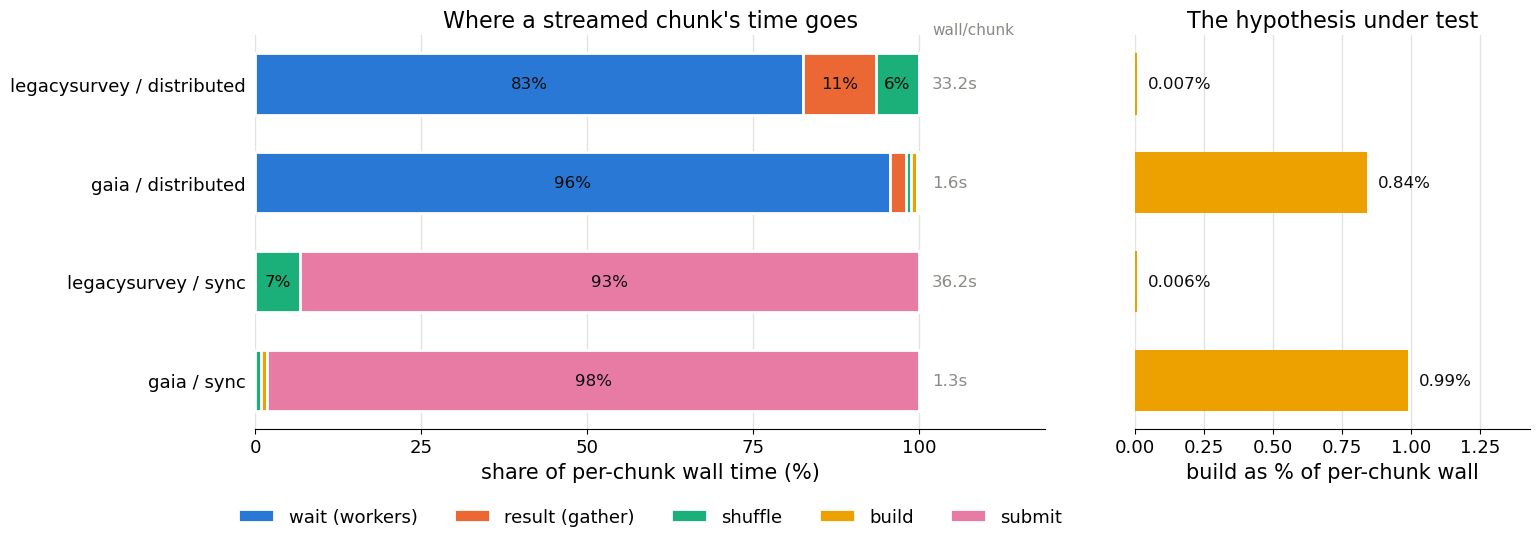

In [12]:
# Reference palette, slots 1-5 in documented order (adjacent-pair CVD gates pass in
# light mode for this ordering; the table above is the required table view).
SERIES = {
    "wait_s":    ("#2a78d6", "wait (workers)"),
    "result_s":  ("#eb6834", "result (gather)"),
    "shuffle_s": ("#1baf7a", "shuffle"),
    "build_s":   ("#eda100", "build"),
    "submit_s":  ("#e87ba4", "submit"),
}
GRAY, INK = "#8a8a85", "#0b0b0b"

plot_df = summary.copy()
# graph_s is sub-millisecond; fold it into submit rather than seat a 6th series.
plot_df["submit_s"] = plot_df["submit_s"] + plot_df["graph_s"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.5, 5.6), width_ratios=[2.0, 1])
y = np.arange(len(plot_df))[::-1]

# Left panel is share-of-wall, not seconds: absolute per-chunk time spans ~45x across
# these configs, so a shared linear second-axis crushes both gaia rows into slivers.
# The absolute wall time is kept as a direct label at the end of each bar.
pct = 100 * plot_df[list(SERIES)].div(plot_df["wall_s"], axis=0)
left = np.zeros(len(plot_df))
for key, (color, label) in SERIES.items():
    vals = pct[key].to_numpy()
    ax1.barh(y, vals, left=left, height=0.62, color=color, label=label,
             edgecolor="white", linewidth=2)  # 2px surface gap between segments
    for yi, v, l in zip(y, vals, left):
        if v > 6:  # direct-label only segments that fit
            ax1.text(l + v / 2, yi, f"{v:.0f}%", ha="center", va="center",
                     fontsize=12, color=INK)
    left += vals

for yi, w in zip(y, plot_df["wall_s"]):
    ax1.text(102, yi, f"{w:.1f}s", va="center", fontsize=12, color=GRAY)
ax1.text(102, y[0] + 0.55, "wall/chunk", va="center", fontsize=11, color=GRAY)

ax1.set_xlim(0, 119)
ax1.set_xticks([0, 25, 50, 75, 100])
ax1.set_yticks(y, plot_df.index)
ax1.set_xlabel("share of per-chunk wall time (%)")
ax1.set_title("Where a streamed chunk's time goes")
ax1.spines[["top", "right", "left"]].set_visible(False)
ax1.grid(axis="x", color="#e2e2de", linewidth=1)
ax1.set_axisbelow(True)
ax1.tick_params(left=False)
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), frameon=False, ncols=5)

# Right panel: emphasis. build is the series under test; this is the sub-1% zoom the
# left panel cannot resolve.
bp = plot_df["build_pct"].to_numpy()
ax2.barh(y, bp, height=0.62, color=SERIES["build_s"][0])
for yi, v in zip(y, bp):
    ax2.text(v + max(bp) * 0.04, yi,
             f"{v:.2f}%" if v >= 0.01 else f"{v:.3f}%",
             va="center", fontsize=12, color=INK)
ax2.set_yticks(y, [""] * len(y))
ax2.set_xlim(0, max(bp) * 1.45)
ax2.set_xlabel("build as % of per-chunk wall")
ax2.set_title("The hypothesis under test")
ax2.spines[["top", "right", "left"]].set_visible(False)
ax2.grid(axis="x", color="#e2e2de", linewidth=1)
ax2.set_axisbelow(True)
ax2.tick_params(left=False)

fig.tight_layout()
fig.savefig("reports/profile-phases.png", dpi=144, bbox_inches="tight")
plt.show()

## Experiment 3 -- when *would* `build` matter?

`build_s` per chunk is `partitions_per_chunk x build_1px`, and `build_1px` grows with
`npartitions` while being completely independent of how many bytes a partition holds.
Everything it competes with -- fetch, gather, shuffle -- scales with bytes.

So the question "is `build` worth fixing for my catalog" reduces to one ratio, and the
crossover below says where a catalog has to sit before `build` reaches 10% of a chunk's
wall time.

In [13]:
per_px_ms = build_df["build_1px_ms"]

cross = []
for name in summary.index:
    cat_key = name.split(" / ")[0]
    row = summary.loc[name]
    mb = row["mb_per_chunk"]
    build_ms = 1e3 * row["build_s"]
    other_s = row["wall_s"] - row["build_s"]
    cross.append(
        {
            "config": name,
            "mb_per_chunk": mb,
            "build_ms_per_chunk": build_ms,
            "non_build_s": other_s,
            # bytes-throughput of everything that is not build
            "mb_per_s_non_build": mb / other_s if other_s else np.nan,
            # MB/chunk at which build would be 10% of wall
            "mb_at_10pct": 9 * (build_ms / 1e3) * (mb / other_s) if other_s else np.nan,
        }
    )

cross_df = pd.DataFrame(cross).set_index("config")
cross_df.round(3)

,mb_per_chunk,build_ms_per_chunk,non_build_s,mb_per_s_non_build,mb_at_10pct
config,,,,,
legacysurvey / distributed,1671.213,2.245,33.243,50.273,1.016
gaia / distributed,10.863,13.292,1.571,6.913,0.827
legacysurvey / sync,1900.409,2.228,36.240,52.439,1.051
gaia / sync,10.863,13.158,1.321,8.221,0.974


## Findings

Measured on `sdfiana012`, lsdb `0.10.5.dev1+g36a32399e`, dask `2026.3.0`, 2 workers,
`partitions_per_chunk = 2`.

### 1. `post_s` is the gather and the shuffle. It is not `build`.

The baseline flagged `post_s` at 18.5% of wall without attributing it. Decomposed, for
`legacysurvey / distributed` (5 steady chunks, `post_s` = 5.78 s of 33.24 s wall = 17.4%,
reproducing the baseline):

| phase | s/chunk | % of wall | **% of `post_s`** |
|---|---|---|---|
| `result` -- `future.result()` gather + deserialize | 3.650 | 11.0% | **63.1%** |
| `shuffle` -- `sample(frac=1)` | 2.130 | 6.4% | **36.8%** |
| `graph` + `submit` | 0.003 | 0.01% | 0.06% |
| **`build`** | **0.0022** | **0.007%** | **0.04%** |

`build` is **2.2 milliseconds**. The hypothesis that it drives `post_s` is off by roughly
2,500x.

The structural point worth keeping: `wait()` returns when the *workers* are done, but the
bytes still have to cross to the client. That transfer is `result_s` -- 3.65 s/chunk, the
largest single component of the main-thread dead time, and it sat on the far side of the
only seam the baseline could reach from outside.

### 2. `build` really is O(npartitions) -- the diagnosis was right, the impact was not

| catalog | npartitions | `build` 1 pixel | whole graph at once | one-at-a-time / whole |
|---|---|---|---|---|
| legacysurvey | 5,488 | 1.088 ms | 0.030 s | **201x** |
| gaia | 33,055 | 6.309 ms | 0.351 s | **595x** |

Per-pixel cost grows **5.80x** against a partition-count ratio of **6.02x** -- linear, as
the source predicts. cProfile confirms the mechanism exactly: **661,140** `HealpixPixel.__hash__`
calls against a predicted `20 builds x 33,055 pixels = 661,100`, about **61%** of `build`'s
runtime spent rejecting pixels it was asked to skip.

So the cost is real. It just never surfaces, because it scales with *partition count* while
everything it competes with scales with *bytes*.

### 3. Which catalogs it could ever matter for

`build` reaches 10% of per-chunk wall only below **~0.8-1.0 MB per chunk**. Gaia carries
10.9 MB/chunk and still only pays 0.84%; legacysurvey carries 1,671 MB and pays 0.007%.
A catalog would have to be roughly **10x thinner than gaia** -- at gaia's partition count --
before this became a throughput concern.

The regime where it does bite is **latency over a full pass**: at 6.3 ms/partition, one
epoch over gaia's 33,055 partitions spends **209 s inside `build`** against **0.35 s** to
build the entire graph once. Invisible at 5 chunks; dominant in a training loop doing real
epochs. That makes the O(len(pixels)) fix a worthwhile cleanup, but **not** the answer to
"why is streaming slow."

### 4. `client=None` has no prefetch overlap at all

With no client, `submit_next_partitions` calls `.compute()` inline, so `submit_s` swallows
the whole fetch (93-98% of wall) and `wait_s` is identically zero. Nothing overlaps with
consumer work. For legacysurvey the two modes came out comparable here only because
Hugging Face throughput moved between them -- see the caveat below.

### Caveat: Hugging Face variance dominates the absolute numbers

`legacysurvey / sync` chunks ranged **18.4 s to 55.3 s** within a single run (3.0x), and its
mean moved **58.0 s -> 36.2 s** between two runs of this notebook an hour apart (1.6x, matching
the spread `bench_stream.py` documents). Treat cross-config *absolute* comparisons here as
indicative only.

None of this touches the conclusion: `build_s` measured **0.0022 s** (legacysurvey) and
**0.0133 s** (gaia) in *both* runs, to three decimal places. It is deterministic CPU work
and does not move with the network.

### Two defects found along the way (not fixed here -- profiling only)

1. **`CatalogStream` docstring is wrong.** "grabs 4 random partitions **5 times** in a row,
   **looping over the data as needed**" describes `InfiniteStream`, not `CatalogStream`.
   `git blame` puts it at `b444efa7` ("split infinite looping into it's own streamer") --
   the prose stayed behind when the behavior moved. `CatalogStream` yields
   `ceil(12/4) = 3` chunks and never loops. The doctest passes because it only checks the
   3 printed values; the English above them is unverified.

2. **`CatalogIterator.__len__` is off by one.** The constructor pre-submits chunk 0, so
   `partitions_left` is already decremented before `len()` reads it:

   | `partitions_per_chunk` | `len()` | chunks actually yielded |
   |---|---|---|
   | 1 | 11 | 12 |
   | 4 | 2 | 3 |
   | 12 | **0** | 1 |

   At `ppc >= npartitions` it reports `0` for a stream that yields data, so
   `for _ in range(len(it))` silently does nothing.